# Transient liquid phase bonding in Ni-P

A phosphorus-rich liquid interlayer first dissolves nickel and widens, then
solidifies as phosphorus diffuses into the solid. We simulate the published Ni-P
case [1, 2] with constant diffusivities and fixed interface compositions, without a database.
The model is planar and isothermal, with equal constant molar volumes and zero-flux boundaries.

Run cells from top to bottom in the `kawin` environment with the package installed.
Start the kernel in this examples directory or at the extraction repository root.
Each notebook is independent; no earlier notebook needs to have been run.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from kawin.diffusion.DiffusionParameters import TemperatureParameters
from moving_boundary.mesh import CartesianFD1D, ProfileBuilder, StepProfile1D
from moving_boundary.mesh.TransformedGrids import two_phase_landau_grids
from moving_boundary.providers.constant import ConstantDiffusivity
from moving_boundary.solvers import MovingBoundaryIllingworthFD1DModel
from moving_boundary.plotting import plot_composition_profiles, plot_interface_history

## Define the half-joint

The left boundary is the joint's symmetry plane. LIQUID lies left of solid FCC_A1.
Compositions are mole fractions of P, lengths are **micrometres**, time is seconds,
and diffusivities are micrometres squared per second [1, p. 213; 2, Table 1].
The constant provider ignores temperature, but the API requires it.

In [ ]:
#NOTES I realize that it's technically fine if all input length units are not in meters but are scaled from meters (e.g., μm) as long as no database-derived values are used and it is remembered that the output results will have their length units scaled similarly. However, I'm not sure if we want the user to get in the habit of inputting things in arbitrarily scaled length units. 
elements = ["NI", "P"]
phases = ["LIQUID", "FCC_A1"]
liquid_initial, solid_initial = 0.19, 0.0
liquid_interface, solid_interface = 0.10223, 0.00166
liquid_diffusivity, solid_diffusivity = 500.0, 18.0   # units: μm^2/s
interface_position, domain_length = 12.5, 3012.5      # units: μm
temperature = 1423.15 # units: K
duration = 7.0e4 # units: s

## Build the mesh and model

The physical mesh has 3013 points. The phase solves use separate 81- and 321-node
transformed grids. Stronger grading in the solid resolves its initially short
diffusion length. These are the existing demonstration settings, not converged results.

In [12]:
mesh = CartesianFD1D(["P"], [0.0, domain_length], 3013)
mesh.setResponseProfile(ProfileBuilder([
    (StepProfile1D(interface_position, liquid_initial, solid_initial), "P")
]))
left_grid, right_grid = two_phase_landau_grids(
    81, 321, method="linear",
    left_kwargs={"spacing_ratio": 0.2}, right_kwargs={"spacing_ratio": 0.01},
)
model = MovingBoundaryIllingworthFD1DModel(
    mesh, elements, phases,
    thermodynamics=ConstantDiffusivity({"LIQUID": liquid_diffusivity, "FCC_A1": solid_diffusivity}),
    temperature=TemperatureParameters(temperature),
    interfacePosition=interface_position,
    interface_compositions=(liquid_interface, solid_interface),
    time_step=1.0, dt_mode="semi_log", semiLog_dt=0.005, semiLogT0=1.0e-6,
    phase_a_nodes=81, phase_b_nodes=321,
    transformed_u_grid=left_grid, transformed_v_grid=right_grid,
    max_iterations=200, record=True, record_pq_data=True,
)

## Simulate widening and solidification

Rebuild the model before repeating the solve. We stop while liquid remains:
this solver does not remove a phase when its width vanishes.

In [13]:
model.solve(duration, minDtFrac=1.0e-14, verbose=True, vIt=500)
print(f"Final liquid half-width: {float(model.getInterfacePosition()):.3f} μm")

Iteration	Sim Time (h)	Run time (s)
0		0.000e+00		0.0
500		3.367e-09		0.3
1000		4.102e-08		0.7
1500		4.997e-07		1.0
2000		6.088e-06		1.4
2500		7.417e-05		1.8
3000		9.035e-04		2.2
3500		1.101e-02		2.5
4000		1.341e-01		2.8
4500		1.634e+00		3.1
4996		1.944e+01		3.4
Final liquid half-width: 2.538 μm


## Plot profiles and liquid thickness

The early peak and subsequent contraction occur on very different time scales,
so the history uses a logarithmic time axis. The profile panels use different
distance windows to make the initial layer and later diffusion field visible.
The final panel uses logarithmic composition to show dilute phosphorus in the solid.

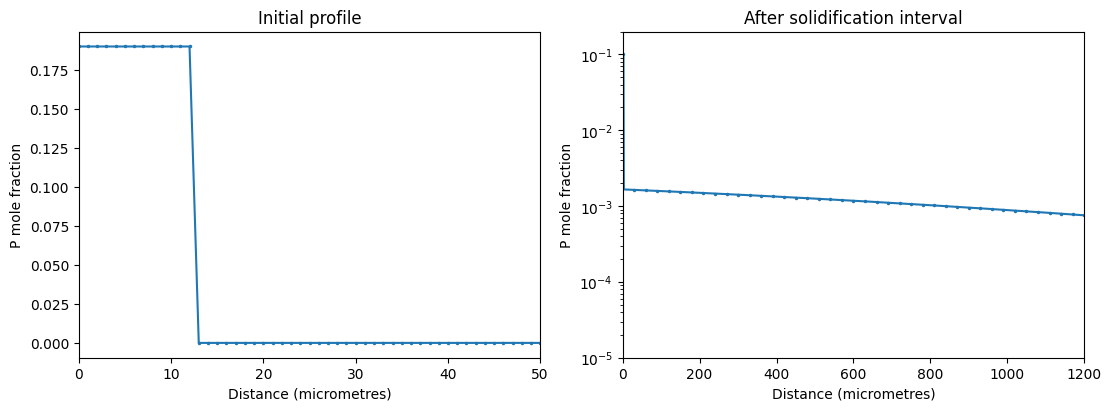

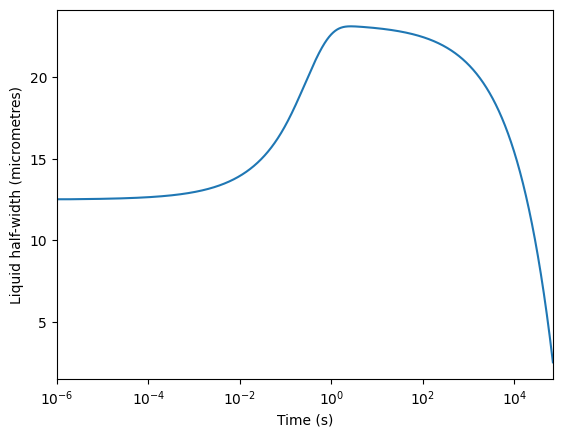

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
plot_composition_profiles(model, time=0.0, ax=axes[0], marker=".", markersize=3)
plot_composition_profiles(model, ax=axes[1], marker=".", markersize=3, markevery=30)
axes[0].set(title="Initial profile", xlim=(0, 50))
axes[1].set(title="After solidification interval", xlim=(0, 1200), yscale="log", ylim=(1.0e-5, 0.2))
for ax in axes:
    ax.set(xlabel="Distance (μm)", ylabel="P mole fraction")
plt.show()

ax = plot_interface_history(model)
ax.set(xscale="log", xlim=(1.0e-6, duration), xlabel="Time (s)",
       ylabel="Liquid half-width (μm)", title="Interface position history")
plt.show()

## Optional: conservation and a width bound

If all initial phosphorus were in liquid at its interface composition, the
half-width would be `s0 * c0 / c_liquid` [1, p. 213]. Some P enters the solid,
so the computed maximum stays below that bound. This and conservation do not
validate the whole time-dependent profile. Detailed early-time exact checks [3]
remain in [the Python workflow](binary_tlp_bonding.py).

In [17]:
from moving_boundary.analytic import recorded_history
from moving_boundary.run_diagnostics import inventory_drift

times, positions = recorded_history(model.interfaceData)
inventories = np.asarray([model.getTotalInventory(float(t)) for t in times])
absolute_drift, relative_drift = inventory_drift(inventories)
width_bound = interface_position * liquid_initial / liquid_interface
peak_width = float(np.max(positions))
print(f"Maximum half-width: {peak_width:.3f}; theoretical upper bound: {width_bound:.3f} μm")
print(f"Maximum relative inventory drift: {relative_drift:.2e}")

Maximum half-width: 23.096; theoretical upper bound: 23.232 μm
Maximum relative inventory drift: 2.62e-11


## Things to try

Double the transformed node counts, adjust the solid grading, or change a
diffusivity and compare the thickness history. Keep every quantity in consistent units.
Use the [resolution-study notebook](fecrni_resolution_study.ipynb) for a systematic comparison pattern.

## References


1. T. C. Illingworth, I. O. Golosnoy, "Numerical solutions of diffusion-controlled moving
   boundary problems which conserve solute," J. Comput. Phys. 209 (2005) 207-225,
   doi:10.1016/j.jcp.2005.02.031. All inputs (p. 213), the width bound (p. 213) and Fig. 3;
   the solver implements this paper's algorithm.
2. Y. Zhou, T. H. North, "Kinetic modelling of diffusion-controlled, two-phase moving
   interface problems," Modell. Simul. Mater. Sci. Eng. 1 (1993) 505-516. The original Ni-P
   bonding case: TLP bonding of nickel with Ni-19 at.% P filler at 1150 C, and its input
   parameters (Table 1).
3. J. S. Kirkaldy, "Diffusion in multicomponent metallic systems: III. The motion of planar
   phase interfaces," Can. J. Phys. 36 (1958) 917-925, doi:10.1139/p58-098. Similarity
   solutions for planar interfaces with constant diffusivities; the early-time check is the
   binary, two-phase case.